# Working with TileDB

This example stores a small generated point cloud in TileDB, reads a selected area, and calculates forest metrics. It also converts a LAS file using streaming and writes canopy-height GeoTIFF tiles.

No data download is needed. Run the cells from top to bottom: the setup creates a new temporary directory, and the last cell removes the example files.

PyForestScan requires the Python `tiledb` package. Reading and writing points also requires PDAL's native TileDB plugin, available from conda-forge as `libpdal-tiledb`. Check that `pdal --drivers` lists both `readers.tiledb` and `writers.tiledb`; see the [installation guide](../installation.md).


In [1]:
%matplotlib inline

from pathlib import Path
from tempfile import TemporaryDirectory

import numpy as np
import rasterio
from rasterio.crs import CRS

from pyforestscan.calculate import calculate_chm
from pyforestscan.handlers import convert_to_tiledb, read_lidar, write_las, write_tiledb
from pyforestscan.process import process_with_tiles
from pyforestscan.tiledb_io import get_tiledb_info
from pyforestscan.visualize import plot_metric

workspace = TemporaryDirectory(prefix="pyforestscan-tiledb-")
workdir = Path(workspace.name)
array_uri = str(workdir / "forest.tiledb")
source_srs = "EPSG:32605"


## Make a small forest point cloud

The scene spans 12 m in each horizontal direction. At every 1 m location, we create one ground point and one canopy point. Ground elevation slopes gently, while canopy height varies smoothly between about 9 and 15 m. `HeightAboveGround` is already known, so later calculations do not need to estimate it.

The array contains `X`, `Y`, `Z`, `HeightAboveGround`, `Classification`, and `Intensity`. Coordinates use the required `float64` dtype; the remaining fields are numeric scalars. One canopy point is repeated to demonstrate that duplicate points are retained. There are 339 points in total.


In [2]:
x, y = np.meshgrid(np.arange(13, dtype=float), np.arange(13, dtype=float), indexing="ij")
x, y = x.ravel(), y.ravel()
ground_z = 100.0 + 0.05 * x + 0.02 * y
canopy_height = 12.0 + 3.0 * np.sin(x / 3.0) * np.cos(y / 4.0)

dtype = [
    ("X", "f8"), ("Y", "f8"), ("Z", "f8"),
    ("HeightAboveGround", "f8"), ("Classification", "u1"), ("Intensity", "u2"),
]
ground = np.zeros(x.size, dtype=dtype)
ground["X"] = 500000.0 + x
ground["Y"] = 2000000.0 + y
ground["Z"] = ground_z
ground["Classification"] = 2
ground["Intensity"] = 100

canopy = ground.copy()
canopy["Z"] = ground_z + canopy_height
canopy["HeightAboveGround"] = canopy_height
canopy["Classification"] = 5
canopy["Intensity"] = (200 + 4 * x + 2 * y).astype("u2")

points = np.concatenate([ground, canopy, canopy[:1]])
print(f"Generated {points.size} points with fields: {points.dtype.names}")


Generated 339 points with fields: ('X', 'Y', 'Z', 'HeightAboveGround', 'Classification', 'Intensity')


## Store and inspect the points

`write_tiledb()` creates an XYZ sparse array and retains the other numeric fields as attributes. Coordinates are not rounded and duplicate points are preserved. Point order after reading is unspecified.

The destination must not already exist. Rerun the setup cell to use a fresh temporary directory if you want to repeat the write.

`get_tiledb_info()` reads metadata without loading the points. Its bounds describe the occupied extent in the order `(xmin, xmax, ymin, ymax, zmin, zmax)`; the CRS is returned as WKT.


In [3]:
write_tiledb(points, array_uri, source_srs, chunk_size=128)
info = get_tiledb_info(array_uri)
print("Occupied bounds:", info["bounds"])
print("CRS:", CRS.from_wkt(info["srs"]).to_string())

arrays = read_lidar(array_uri, source_type="tiledb")
restored_count = sum(array.size for array in arrays)
assert restored_count == points.size
print(f"Read back {restored_count} points, including the duplicate.")


Occupied bounds: (500000.0, 500012.0, 2000000.0, 2000012.0, 100.0, 115.2362238732553)
CRS: EPSG:32605


Read back 339 points, including the duplicate.


## Read a selected area

Use XY bounds to select an area in the stored coordinate system. A third bounds pair can also restrict Z elevation. `read_lidar()` returns a list of structured NumPy arrays, or `None` if no points match.

A read loads all selected points into memory. Bounds keep this manageable for larger datasets; omitting them reads the entire array.


In [4]:
query_bounds = ([500002.0, 500008.0], [2000002.0, 2000008.0])
selected_arrays = read_lidar(
    array_uri,
    source_type="tiledb",
    bounds=query_bounds,
)
if selected_arrays is None:
    raise RuntimeError("The example query unexpectedly returned no points.")
selected = np.concatenate(selected_arrays)
print(f"Selected {selected.size} points.")


Selected 98 points.


## Calculate a canopy height model

The selected points contain `HeightAboveGround`, so they can be passed directly to `calculate_chm()`. We use 1 m cells and leave interpolation disabled.

TileDB's storage tiles do not set this resolution. The calculation's `cell_resolution` determines the CHM grid.


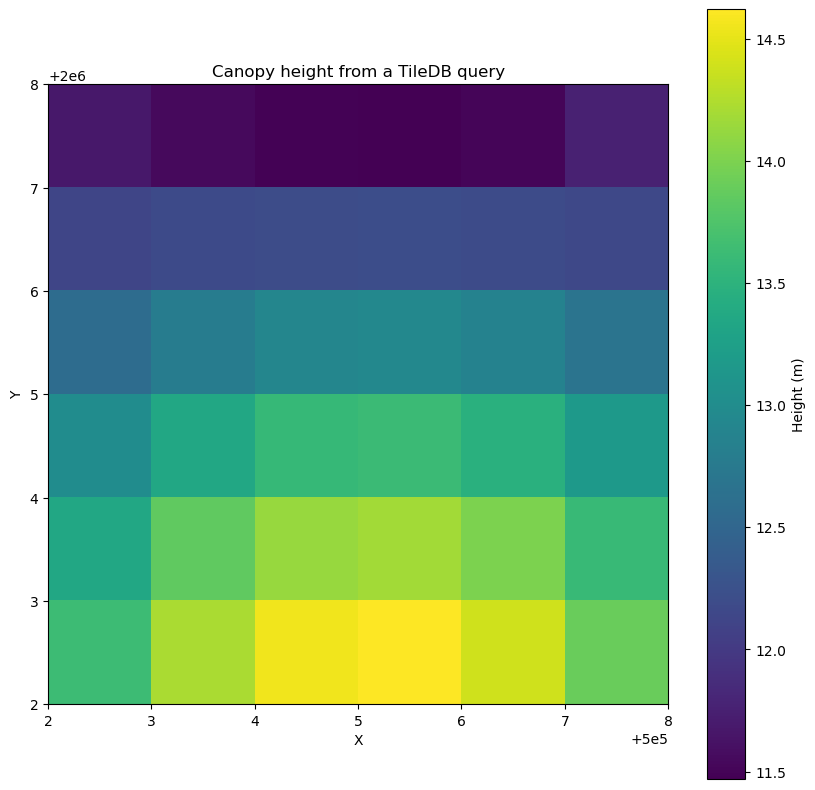

In [5]:
cell_resolution = (1.0, 1.0)
chm, extent = calculate_chm(selected, cell_resolution, interpolation=None)
plot_metric(
    "Canopy height from a TileDB query", chm, extent,
    metric_name="Height (m)", cmap="viridis",
)


## Stream a LAS file into TileDB

For a dataset already stored as LAS, LAZ, COPC, or EPT, use `convert_to_tiledb()` to avoid loading the complete source into NumPy. It returns the number of points written. `chunk_size` controls batches of points, not voxel resolution.

Here we create a tiny LAS file from the same scene so the example is self-contained. The LAS file has its own coordinate encoding; conversion preserves the coordinates read from that source. The source CRS is retained, and `srs` can provide a fallback when source metadata lacks it.


In [6]:
las_path = str(workdir / "source.las")
converted_uri = str(workdir / "converted.tiledb")
write_las(points, las_path, srs=source_srs, compress=False)
converted_count = convert_to_tiledb(
    las_path,
    converted_uri,
    srs=source_srs,
    chunk_size=128,
)
assert converted_count == points.size
print(f"Streamed {converted_count} points from LAS to TileDB.")


Streamed 339 points from LAS to TileDB.


## Write forest-metric GeoTIFF tiles

`process_with_tiles()` queries each area with a buffer and writes one GeoTIFF per tile. It reads occupied bounds and CRS from the TileDB metadata. The first argument is the array URI; `source_type="tiledb"` selects the reader.

We calculate 1 m CHM pixels in tiles 6 m across. Heights are already present, so `hag=False` is appropriate. For clouds without `HeightAboveGround`, choose height normalization with `hag=True` or `hag_dtm=True` and a DTM.

Canopy cover, PAI, FHD, and rumple use the same metric arguments as other tiled inputs. For rumple, specify both the fine `voxel_size` and the coarser `rumple_resolution`; see the [rumple guide](../usage/forest-structure/rumple.md).


In [7]:
output_path = workdir / "chm_tiles"
process_with_tiles(
    array_uri,
    tile_size=(6.0, 6.0),
    output_path=str(output_path),
    metric="chm",
    voxel_size=(1.0, 1.0, 1.0),
    source_type="tiledb",
    hag=False,
    interpolation=None,
)

tile_paths = sorted(output_path.glob("*.tif"))
print(f"Created {len(tile_paths)} GeoTIFF tiles.")
for path in tile_paths:
    with rasterio.open(path) as dataset:
        print(path.name, "shape:", dataset.shape, "pixel size:", dataset.res, "CRS:", dataset.crs)


Processing tiles:   0%|          | 0/4 [00:00<?, ?it/s]

Processing tiles:  25%|██▌       | 1/4 [00:00<00:00,  5.50it/s]

Processing tiles:  75%|███████▌  | 3/4 [00:00<00:00,  8.60it/s]

Processing tiles: 100%|██████████| 4/4 [00:00<00:00,  8.65it/s]

Created 4 GeoTIFF tiles.
tile_0_0_chm.tif shape: (4, 4) pixel size: (1.0, 1.0) CRS: EPSG:32605
tile_0_1_chm.tif shape: (4, 4) pixel size: (1.0, 1.0) CRS: EPSG:32605
tile_1_0_chm.tif shape: (4, 4) pixel size: (1.0, 1.0) CRS: EPSG:32605
tile_1_1_chm.tif shape: (4, 4) pixel size: (1.0, 1.0) CRS: EPSG:32605


## Storage and cleanup

The [TileDB guide](../usage/tiledb.md) also covers S3 URIs and configuration files. These APIs work with XYZ sparse point-cloud arrays; dense raster arrays and managed TileDB Cloud URIs are outside their scope.

For storage details, see PDAL's [TileDB reader](https://pdal.io/en/stable/stages/readers.tiledb.html) and [writer](https://pdal.io/en/stable/stages/writers.tiledb.html), and TileDB's [configuration documentation](https://documentation.cloud.tiledb.com/academy/structure/arrays/tutorials/basics/configuration/).

The final cell removes only the temporary files created by this notebook. Use a permanent output directory in your own workflow to keep the arrays and GeoTIFFs.


In [8]:
workspace.cleanup()
print("Removed the temporary example files.")


Removed the temporary example files.
